# Compare the dummy and logistic baselines: deduplicated Subset data

Does learning from age, sex and site improve on giving everyone the training data's malignant-image rate? This short walkthrough introduces two simple metadata models; metadata means the recorded information alongside an image.

[03_patient_fold_verification.ipynb](03_patient_fold_verification.ipynb) supplies the patient groups. [05_metadata_models.ipynb](05_metadata_models.ipynb) expands this comparison to five methods.

The saved logistic model has average precision (AP) 0.0430, versus 0.0184 (pooled); historical mean-fold AP is 0.0567 versus 0.0189 for the dummy. At a cutoff of 0.50, both leave every image unflagged. The reserved test is not used.

For metric definitions, see the [short concept guide](../concepts.md).


**Deduplicated workflow adaptation.** This notebook uses the frozen `dedup_v1` development manifest and original patient assignments. It reads saved clean artifacts; executing it starts no training and does not load the reserved test. The original notebook is preserved as the presentation template: [04_dummy_logistic_baseline.ipynb](../Subset/04_dummy_logistic_baseline.ipynb).

The historical fixed-model comparison used **unweighted mean outer-fold AP**. Current tables lead with **unweighted mean outer-fold ROC-AUC**. The original pooled tables and figures are retained for presentation consistency and are explicitly secondary; their values are not interchangeable with mean-fold scores.

**Current reporting priority:** primary unweighted mean outer-fold ROC-AUC, followed by secondary AP, log loss and Brier. Pooled curves support the comparison. Verified versioned baseline diagnostics supply the dummy/logistic predictions; stage 05 uses matching fixed-family version-2 predictions. Original AP-era numerical examples, ablations, age illustrations and exploratory cutoffs below remain clearly historical supporting evidence. No all-development fit is recreated.

## Context and methods

The prevalence dummy returns the malignant-image rate in its training data. Logistic regression learns weights for age, sex and site categories, combines them and produces a score between 0 and 1. Neither method reads image pixels.

A fold is a group of patients. We train on four folds and predict the fifth, five times. These out-of-fold (OOF) predictions are made without training on the scored patient's images. Category encoding is learned separately within training. Diagnosis and benign/malignant labels reveal the answer; identifiers and fold numbers are also excluded from inputs.

AP measures how well malignant images concentrate near the top of the score ranking; it is not classification accuracy. ROC-AUC measures how often a malignant image scores above a benign one; 0.5 is chance-level ranking. Larger values are better for both. Scores in [0,1] are probability estimates whose calibration, agreement with observed rates, still needs checking.

We show decisions at 0.50, then choose an exploratory logistic cutoff from the same OOF labels. That illustrates a trade-off but can overstate future performance. Notebook 08 later separates cutoff selection from assessment.


## Data

### 1. Load and check the patient folds

The counts below describe the same 6,706 development images used in notebook 03. We check that each patient belongs to one preserved fold and match saved clean predictions. Exact pixel-copy removal retains all 422 patients and 88 malignant patients; 158 copies were removed, leaving 6,706 images and 127 malignant images. The reserved test data is not loaded.


In [2]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "src/melanoma_detection").is_dir() and (p / "pyproject.toml").is_file())
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from melanoma_detection.metadata_tuning_v2_reporting import (
    load_tuning, load_baseline_report, render_section, render_baseline_section,
    display_historical_cell, display_historical_source, original_snapshot,
)
plt.rcdefaults()

ORIGINAL_EXPORT_DPI = 150
NN_COMPARISON_COLORS = ['#2563EB', '#D97706', '#D97706', '#D97706', '#303030']
report = load_baseline_report(PROJECT_ROOT, 'dedup_v1', '04', run_id='roc_auc_grid36_v1')
report["export_dpi"] = ORIGINAL_EXPORT_DPI
display(Markdown("**Version-2 saved-results report:** " + report["status"] +
    ". ROC-AUC is primary; AP and probability errors are secondary. No training, final fitting or reserved-test loading starts here."))


**Version-2 saved-results report:** complete. ROC-AUC is primary; AP and probability errors are secondary. No training, final fitting or reserved-test loading starts here.

## Results

### 2. Load and verify held-out probabilities

The saved clean methods trained and predicted on exactly the same patient splits. The dummy gives one constant probability within each fold. Its five printed probabilities differ slightly because each training fold has a slightly different malignant-image rate.


In [3]:
render_baseline_section(report, 'inputs')

,images,patients,malignant_images
fold,,,
0,1344,84,24
1,1366,84,26
2,1328,87,26
3,1371,82,25
4,1297,85,26


Image, patient, fold and target identities match the frozen development records. Baseline probabilities have verified diagnostic provenance.

### 3. Compare ranking scores

Read the pooled OOF scores as the result across all held-out images. The mean fold ROC-AUC averages the five separate fold scores. They need not be identical. The added mean-fold table is primary for this clean workflow; mean-fold AP is 0.0189 for the dummy and 0.0567 for logistic regression. The following table also checks that the dummy has exactly 0.5 ROC-AUC within each fold, as expected for a constant score.


In [4]:
render_baseline_section(report, 'metrics')

,,roc_auc,average_precision,log_loss,brier_score,fold_auc_sd,fold_ap_sd
scope,model,,,,,,
mean_fold,Prevalence dummy,0.50000,0.01895,0.09393,0.01859,0.00000,0.00091
pooled,Prevalence dummy,0.48774,0.01839,0.09389,0.01858,0.00000,0.00091
mean_fold,Logistic regression,0.59695,0.05669,0.09244,0.01849,0.07893,0.02288
pooled,Logistic regression,0.59429,0.04296,0.09237,0.01848,0.07893,0.02288


In [5]:
render_baseline_section(report, 'dummy_check')

,fold,training_prevalence_score,held_out_malignant_share,secondary_dummy_ap,dummy_roc_auc
0,0,0.01921,0.01786,0.01786,0.5
1,1,0.01891,0.01903,0.01903,0.5
2,2,0.01878,0.01958,0.01958,0.5
3,3,0.01912,0.01823,0.01823,0.5
4,4,0.01867,0.02005,0.02005,0.5


### 4. Read the ROC and precision-recall curves

Blue is logistic regression; grey is the dummy. Each curve traces changing cutoffs. Axis values are fractions: 0.2 means 20%.

- **Left: ROC.** The horizontal axis is benign images wrongly flagged; the vertical axis is malignant images found (recall). Closer to the upper-left is better. The dashed diagonal marks chance ranking.
- **Right: precision-recall.** Recall is horizontal. Precision, the malignant share among flagged images, is vertical. Higher precision at the same recall means fewer false alarms. The dashed horizontal line marks the 1.89% malignant-image share. The endpoint at recall zero does not establish perfect detection.

Logistic regression ranks better than the dummy, but precision remains low across most of the range.


**Historical supporting section:** its saved pre-migration diagnostic is retained below; it does not select the current final procedure.

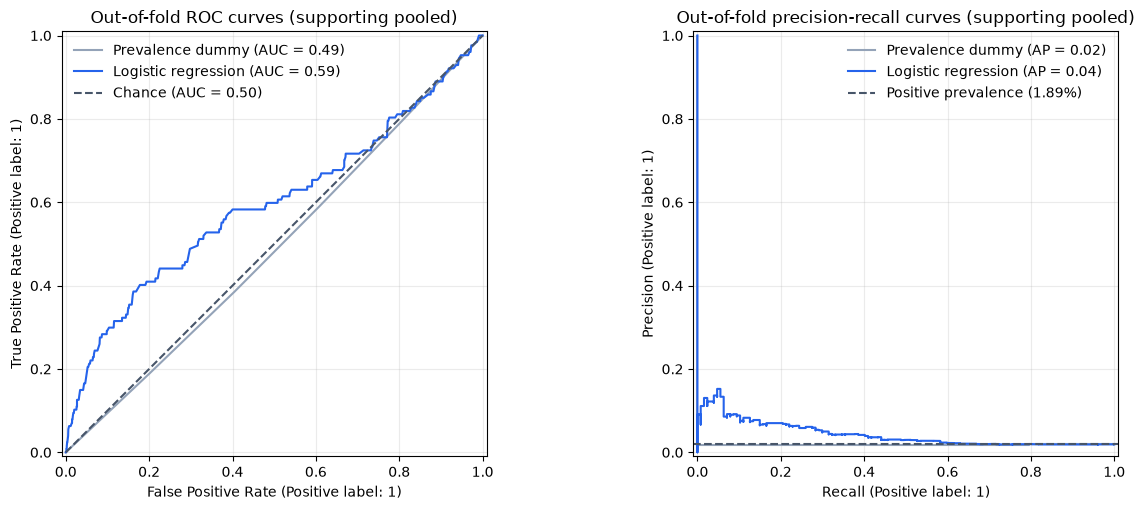

In [6]:
render_baseline_section(report, 'curves')

### 5. Choose an exploratory cutoff

A cutoff turns a probability into a flag. At 0.50, both models leave every image unflagged. Their scores are mostly small because malignant images are rare.

For the logistic model, we also try its distinct probabilities as candidate cutoffs and choose the one with the highest balanced accuracy. This averages recall and specificity, the fraction of benign images left unflagged, giving both classes equal weight. The dummy stays at 0.50 because its constant score provides no useful within-fold ranking.

The same OOF labels choose and assess the logistic cutoff, so its result is exploratory. It has not been checked on an independent final test.


**Historical supporting section:** its saved pre-migration diagnostic is retained below; it does not select the current final procedure.

In [7]:
display_historical_cell(PROJECT_ROOT, 'dedup_v1', '04', 13)

**Historical supporting diagnostic:** saved output of pre-migration `notebooks/Subset_dedup/04_metadata_baselines.ipynb`, cell 13. Its AP-era interpretation and fitted age illustration are preserved; no model is fitted to recreate it.

Default 0.50 threshold:



,Threshold,TN,FP,FN,TP
Model,,,,,
Prevalence dummy,0.5,6579,0,127,0
Logistic regression,0.5,6579,0,127,0


Selected logistic threshold: 0.027186
Balanced accuracy at the selected threshold: 0.6119



### 6. Read the confusion matrices

Each matrix shows the decisions made at the cutoff printed above it. Rows are the actual class and columns are the predicted class. TN is a benign image left unflagged; FP is a benign image flagged by mistake. FN is a missed malignant image; TP is a malignant image found.

The percentages add to 100% within each row: the top row describes benign images and the bottom row describes malignant images. Compare TP with FN to see how many malignant cases are found or missed, then check FP to see the false-alarm cost. Darker blue represents more images, but each panel has its own colour scale, so compare the printed numbers across models.

This figure makes the cutoff trade-off concrete. The logistic model finds 51 of 127 malignant images (40.2%) and wrongly flags 1,170 of 6,579 benign images (17.8%). Only 4.2% of its flagged images are malignant.


**Historical supporting section:** its saved pre-migration diagnostic is retained below; it does not select the current final procedure.

**Historical supporting diagnostic:** saved output of pre-migration `notebooks/Subset_dedup/04_metadata_baselines.ipynb`, cell 15. Its AP-era interpretation and fitted age illustration are preserved; no model is fitted to recreate it.

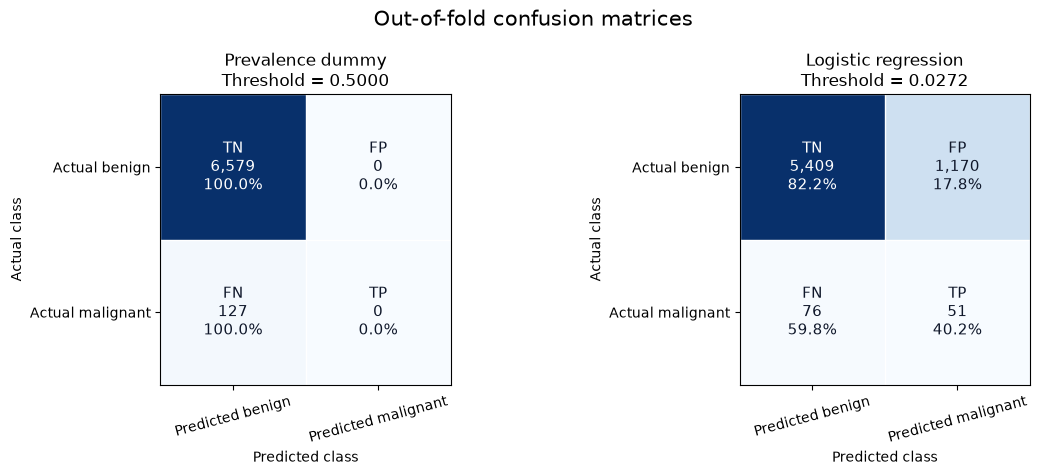

,Threshold,TN,TN % of actual benign,FP,FP % of actual benign,FN,FN % of actual malignant,TP,TP % of actual malignant,Precision among predicted malignant (%)
Model,,,,,,,,,,
Prevalence dummy,0.5000,6579,100.0000,0,0.0000,127,100.0000,0,0.0000,0.0000
Logistic regression,0.0272,5409,82.2161,1170,17.7839,76,59.8425,51,40.1575,4.1769


In [8]:
display_historical_cell(PROJECT_ROOT, 'dedup_v1', '04', 15)

## Limitations

This is a short development comparison of two fixed models. It does not establish the best metadata model or provide uncertainty intervals for their difference. The same patient folds have also guided the wider model comparison, so later model choices based on these scores may look optimistic.

The logistic cutoff is selected and assessed using the same OOF labels. Its confusion matrix illustrates a possible trade-off; it cannot establish how well that cutoff will work on new patients. The low malignant-image rate also means a model can make few overall errors while missing many malignant cases.

Age, sex and site do not describe lesion appearance. These results do not establish calibrated risks, causation, clinical safety or performance on the reserved test set. See notebook 08 for the later uncertainty and cutoff checks.


**Historical supporting section:** its saved pre-migration diagnostic is retained below; it does not select the current final procedure.

## Summary

**Historical fixed-model interpretation:** the AP-era numerical examples and retained-model recommendation below describe the preserved comparison. The current ROC-AUC-first recap follows separately.

Logistic regression improves AP from 0.0184 to 0.0430 and pooled ROC-AUC from 0.4877 to 0.5943. The dummy has ROC-AUC 0.5 within every fold; its pooled value shifts slightly because training-fold prevalences differ.

On the primary mean-fold measure, AP is 0.0189 for the dummy and 0.0567 for logistic regression. Keep the dummy as a reference and logistic regression as a simple comparison. Its exploratory cutoff finds some malignant images with many false alarms; this is not a clinical rule.

Next, [05_metadata_models.ipynb](05_metadata_models.ipynb) compares more flexible models, [06_metadata_neural_network.ipynb](06_metadata_neural_network.ipynb) tests a small network, and [08_metadata_robustness.ipynb](08_metadata_robustness.ipynb) checks uncertainty and training-selected cutoffs.


**Historical supporting section:** its saved pre-migration diagnostic is retained below; it does not select the current final procedure.

## Additional deduplicated-workflow diagnostics

The complete original section sequence above is retained as the template. The following clearly labelled additions document clean artifact verification, training support and explanatory diagnostics that were not figures in the original. They remain secondary development evidence and do not select another model or cutoff.

**Historical supporting section:** its saved pre-migration diagnostic is retained below; it does not select the current final procedure.

In [9]:
display_historical_cell(PROJECT_ROOT, 'dedup_v1', '04', 19)

**Historical supporting diagnostic:** saved output of pre-migration `notebooks/Subset_dedup/04_metadata_baselines.ipynb`, cell 19. Its AP-era interpretation and fitted age illustration are preserved; no model is fitted to recreate it.

,Dataset identity,New CPU fits,Reused clean fits,Images with matching predictions,Reserved test loaded
0,0562e7bb898ab69d2e5ac7fcf50bf6e9b80663362af4ae...,695,60,6706,False


In [10]:
display_historical_cell(PROJECT_ROOT, 'dedup_v1', '04', 20)

**Historical supporting diagnostic:** saved output of pre-migration `notebooks/Subset_dedup/04_metadata_baselines.ipynb`, cell 20. Its AP-era interpretation and fitted age illustration are preserved; no model is fitted to recreate it.

No saved output was recorded for this historical cell; it is not reconstructed by fitting.

### Added diagnostic: 7. Inspect saved logistic associations and state the limits

Coefficients describe regularised associations among encoded categories; they are neither causes nor stable patient risk factors. A category absent from one training fold has no coefficient in that fit. Error bars below show variability across available saved fits, not sampling confidence intervals. This remains a development comparison before image information.

**Historical supporting section:** its saved pre-migration diagnostic is retained below; it does not select the current final procedure.

**Historical supporting diagnostic:** saved output of pre-migration `notebooks/Subset_dedup/04_metadata_baselines.ipynb`, cell 22. Its AP-era interpretation and fitted age illustration are preserved; no model is fitted to recreate it.

,mean,std,count
encoded_feature,,,
categorical__sex_female,-1.1640,0.0555,5
categorical__age_approx_35,-0.9953,0.2193,5
categorical__sex_male,-0.9412,0.1134,5
categorical__age_approx_40,-0.8113,0.2946,5
categorical__anatom_site_general_challenge_palms/soles,-0.8039,0.0365,5
categorical__age_approx_25,-0.7276,0.1442,5
categorical__anatom_site_general_challenge_lower extremity,-0.7093,0.1185,5
categorical__anatom_site_general_challenge_torso,-0.6823,0.0855,5
categorical__age_approx_45,-0.6294,0.1410,5


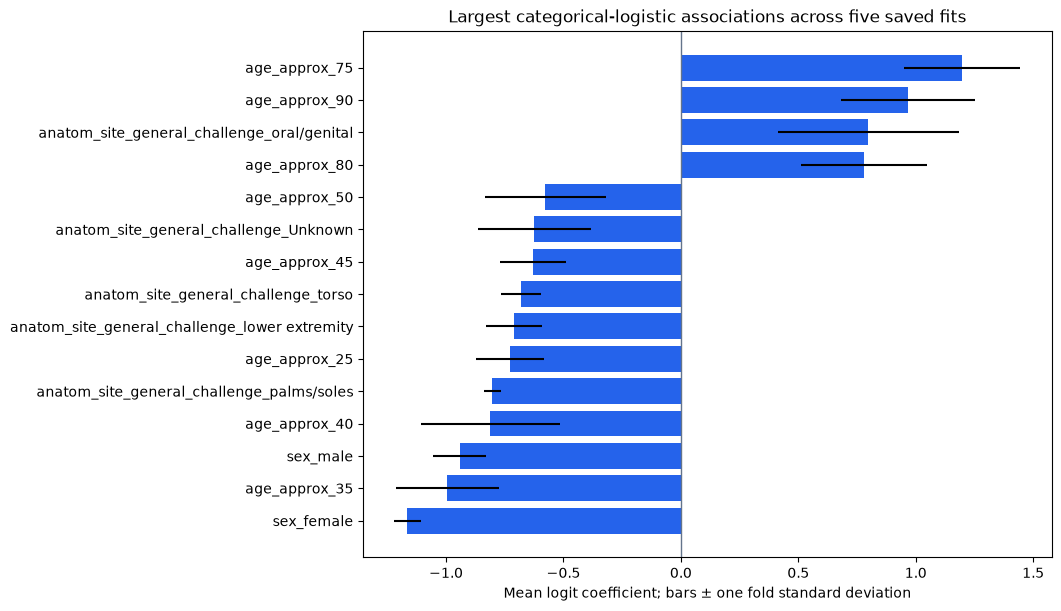

<IPython.core.display.Markdown object>


In [11]:
display_historical_cell(PROJECT_ROOT, 'dedup_v1', '04', 22)

### Current ROC-AUC-first recap

Read the mean-fold ROC-AUC comparison first. Keep rare-positive AP, probability error, patient support and the historical diagnostics alongside it. The comparison supplies development evidence rather than a new final model or test result.

In [12]:
render_baseline_section(report, 'summary')

**Primary mean-fold ROC-AUC:** Prevalence dummy 0.5000; Logistic regression 0.5969. AP, log loss and Brier remain secondary; pooled curves support interpretation. These are patient-held-out development comparisons. Historical ablations, cutoffs and age illustrations are separately labelled supporting diagnostics. A point ordering does not automatically choose a final model; no all-development fit or reserved-test evaluation is performed.